# Cross-Class Feature Exploration: Soccer vs. Baseball vs. Basketball
**Author:** Chris Yang

This standalone notebook systematically analyzes and compares all 12 survey features across the three target sports using cross-class bar charts and box plots to identify predictive features for model selection.

In [1]:
import re
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load data directly if not already in memory
if 'df' not in globals():
    df = pd.read_csv('csc311_project_training_202609.csv')

eda_df = df.copy()

# 2. Rename columns to standard short names if needed
rename_map = {
    'How easy do you think it would be for someone with no prior experience to start playing this sport recreationally? Rate it on a scale from 0 to 10, where 0 means extremely difficult and 10 means extremely easy.': 'difficulty_rating',
    'Success in this sport depends heavily on strategy and planning.': 'strategy_importance',
    'Players must be comfortable with a high risk of injury.': 'injury_risk_comfort',
    'Individual brilliance can outweigh teamwork in this sport.': 'individual_brilliance',
    'Where might you play this sport?': 'play_location',
    'During which seasons would you be most likely to play this sport recreationally in Toronto?': 'play_season',
    'What types of music do you most associate with this sport?': 'associated_music',
    'What foods and drinks do you associate with watching this sport in the place or culture you know best?': 'associated_foods_drinks',
    'What colour do you associate with this sport?': 'associated_color',
    'Which song do you associate with this sport?': 'associated_song',
    'How do you feel when you watch this sport?': 'emotional_response',
    'How much would you be willing to pay for a decent seat at a professional competition of this sport?': 'acceptable_price',
    'label': 'target_sport'
}
for old_col, new_col in rename_map.items():
    if old_col in eda_df.columns:
        eda_df = eda_df.rename(columns={old_col: new_col})

label_col = 'target_sport' if 'target_sport' in eda_df.columns else 'label'

# 3. Clean price feature
def clean_ticket_price(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if s in ['', 'none', 'n/a', 'na', 'null', '-', 'no']:
        return np.nan
    if 'free' in s or s == '0':
        return 0.0
    m_range = re.findall(r'(\d+(?:\.\d+)?)\s*(?:-|to)\s*(\d+(?:\.\d+)?)', s)
    if m_range:
        return (float(m_range[0][0]) + float(m_range[0][1])) / 2.0
    nums = re.findall(r'(\d+(?:,\d{3})*(?:\.\d+)?)', s)
    if nums:
        return float(nums[0].replace(',', ''))
    return np.nan

eda_df['price_clean'] = eda_df['acceptable_price'].apply(clean_ticket_price)
eda_df['log_price'] = np.log1p(eda_df['price_clean'])
eda_df['difficulty_rating'] = pd.to_numeric(eda_df['difficulty_rating'], errors='coerce')

# 4. Map Likert scales (1-5)
likert_map = {
    'Strongly disagree': 1,
    'Disagree': 2,
    'Neutral': 3,
    'Agree': 4,
    'Strongly agree': 5
}
for col in ['strategy_importance', 'injury_risk_comfort', 'individual_brilliance']:
    eda_df[f'{col}_num'] = eda_df[col].map(likert_map)

print(f'Data ready: {len(eda_df)} rows loaded and preprocessed.')



Data ready: 870 rows loaded and preprocessed.


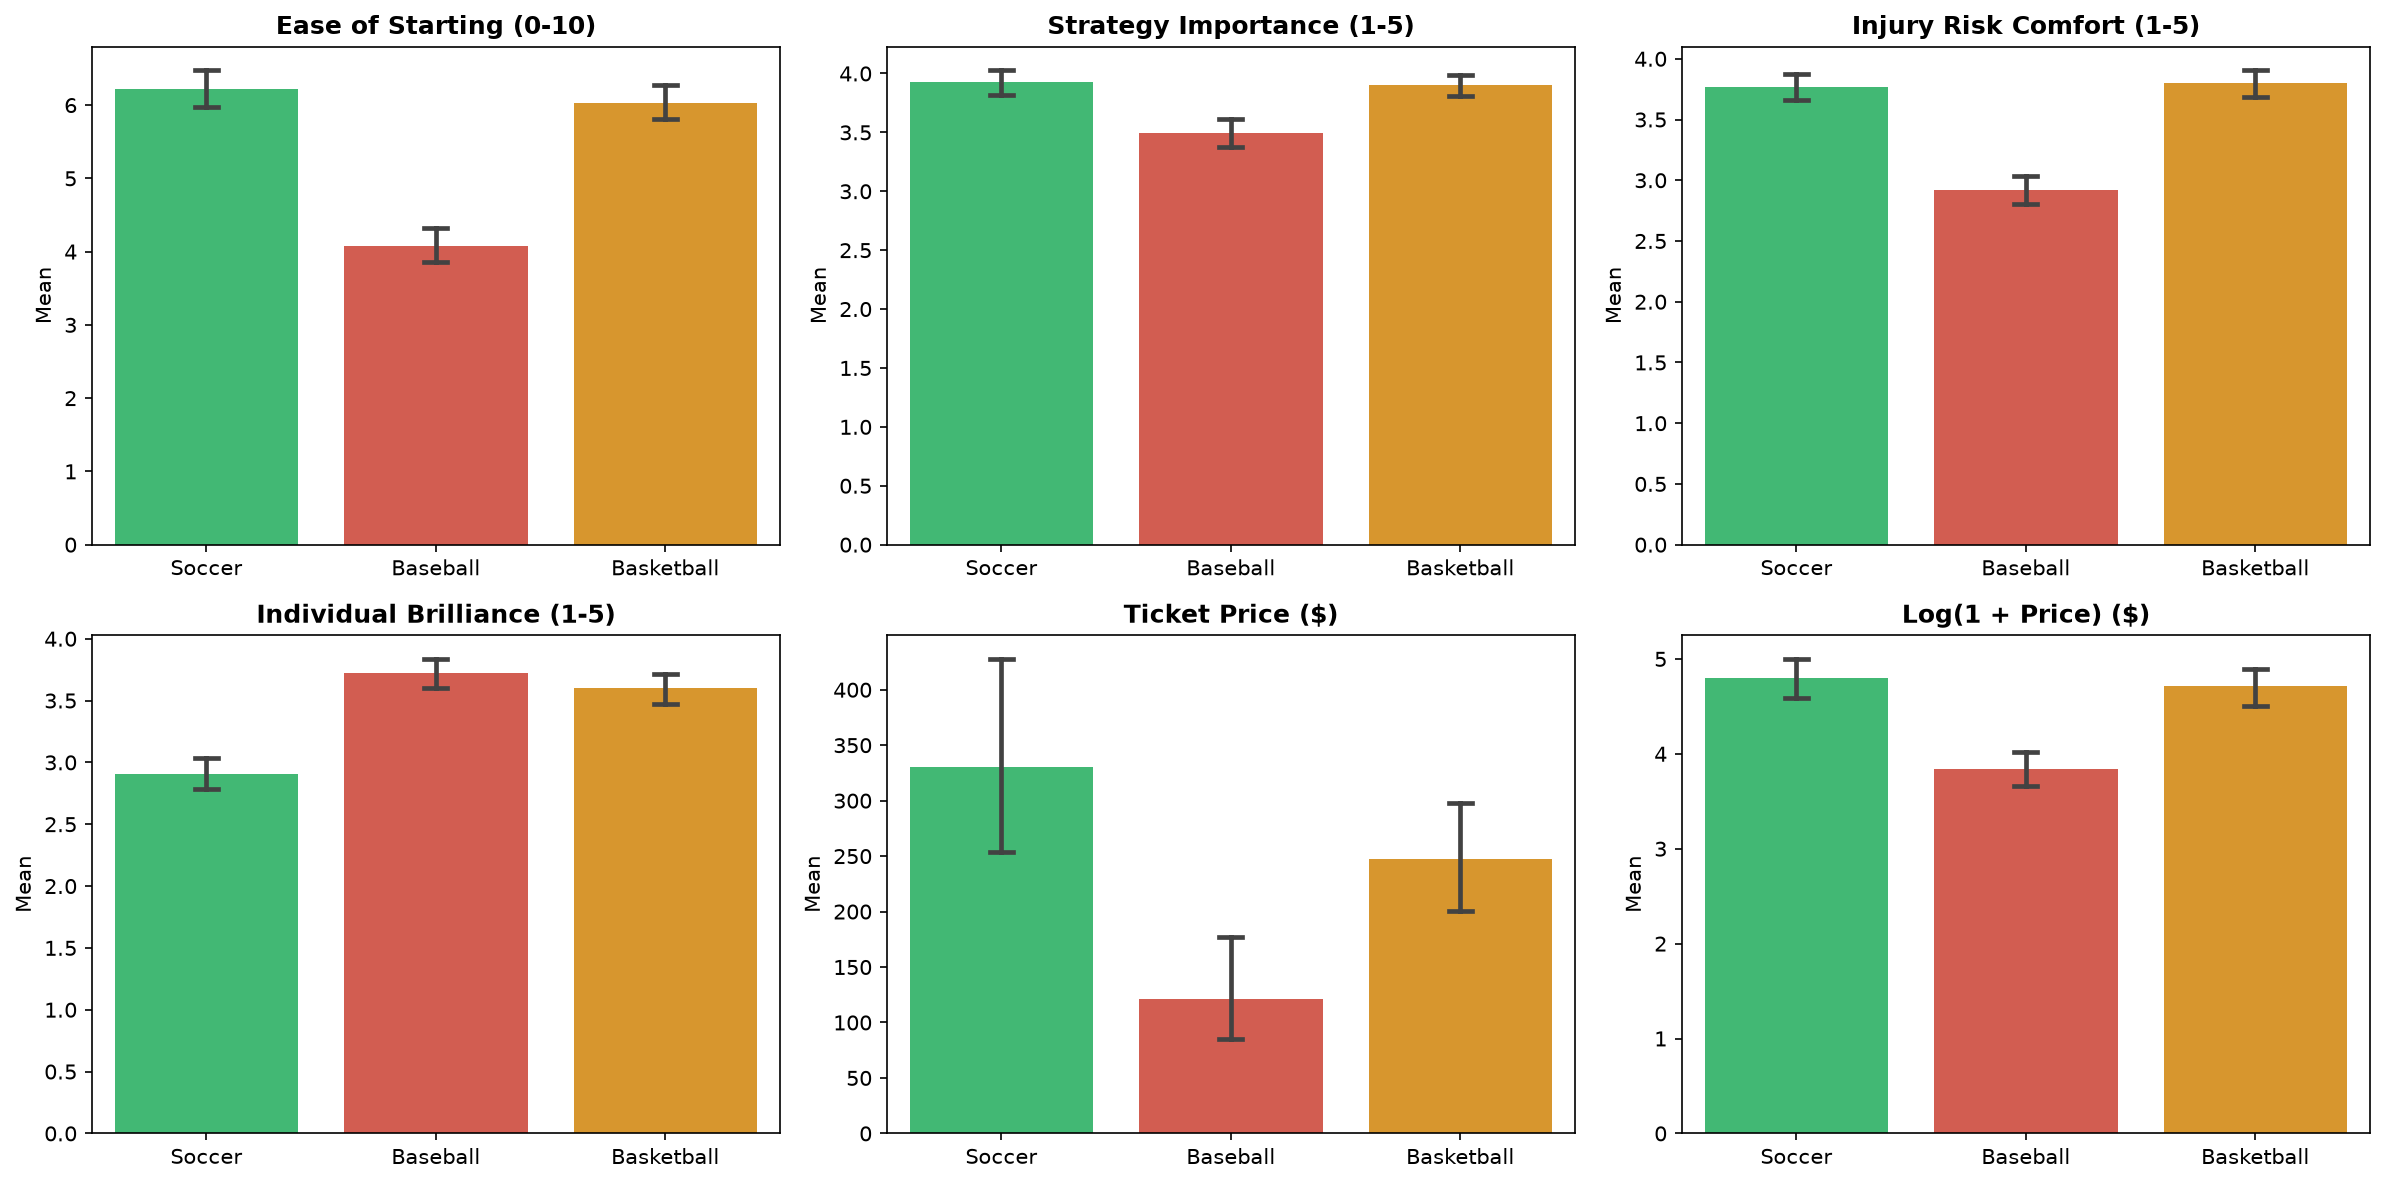

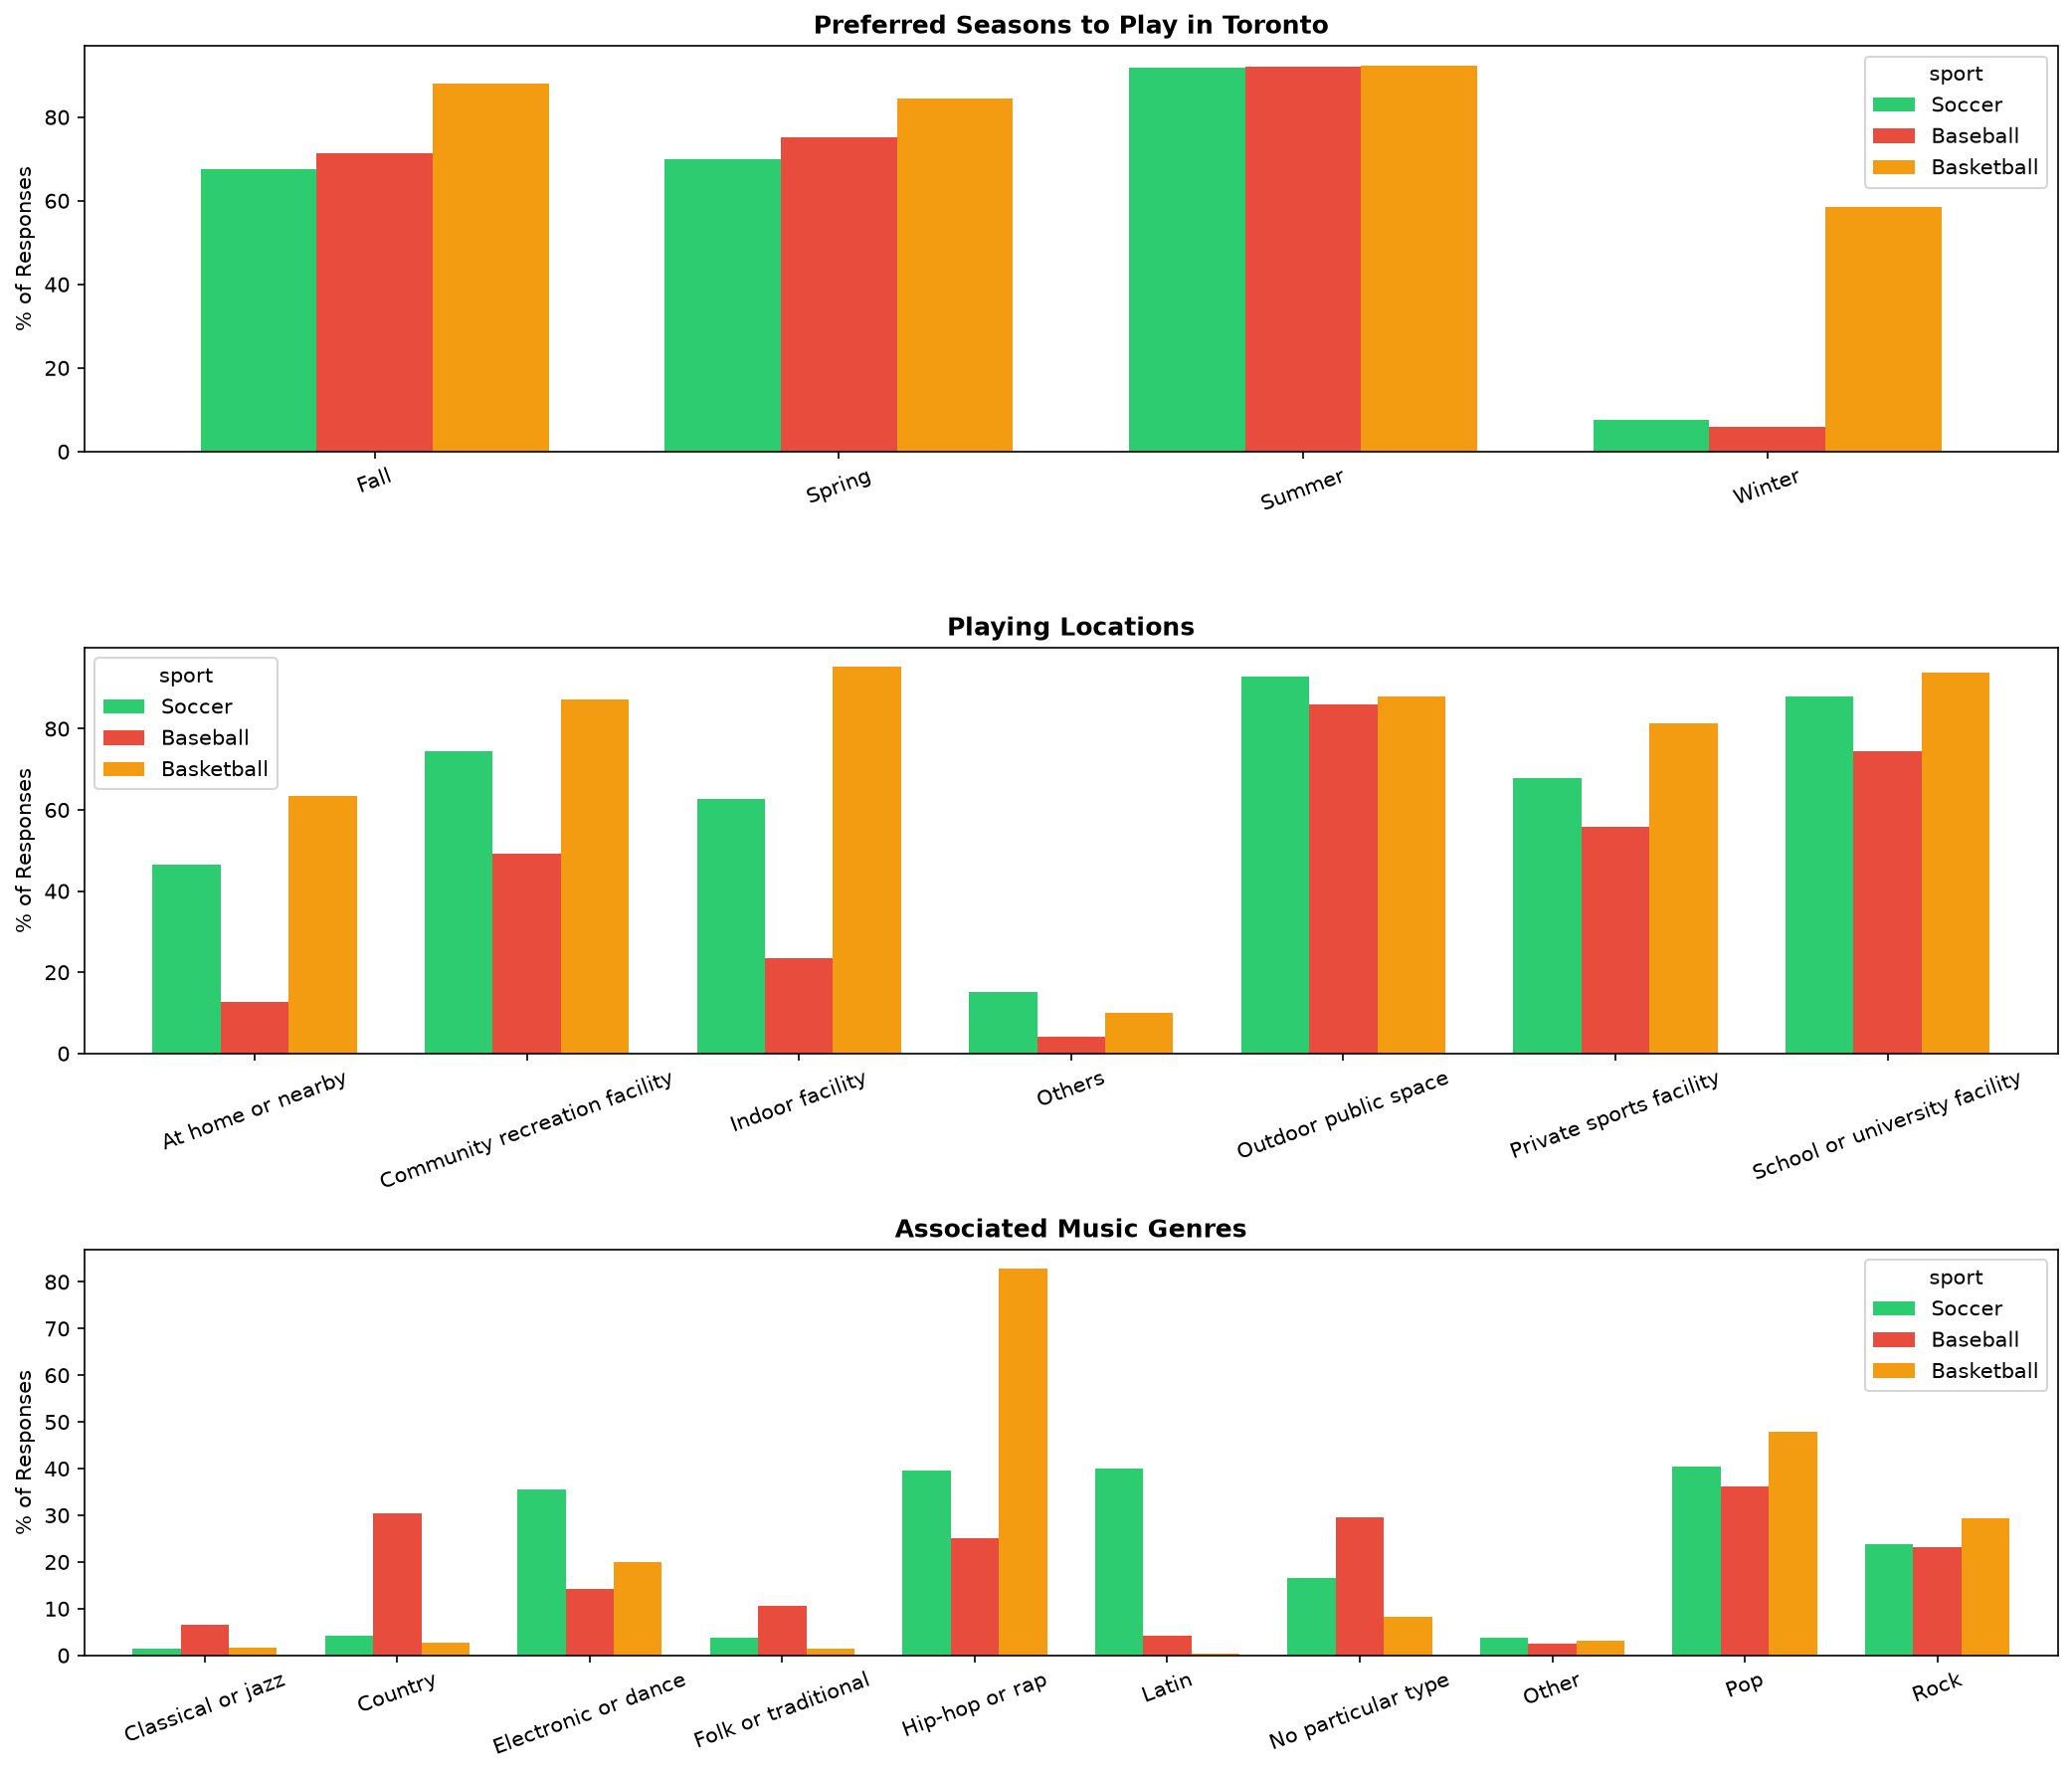

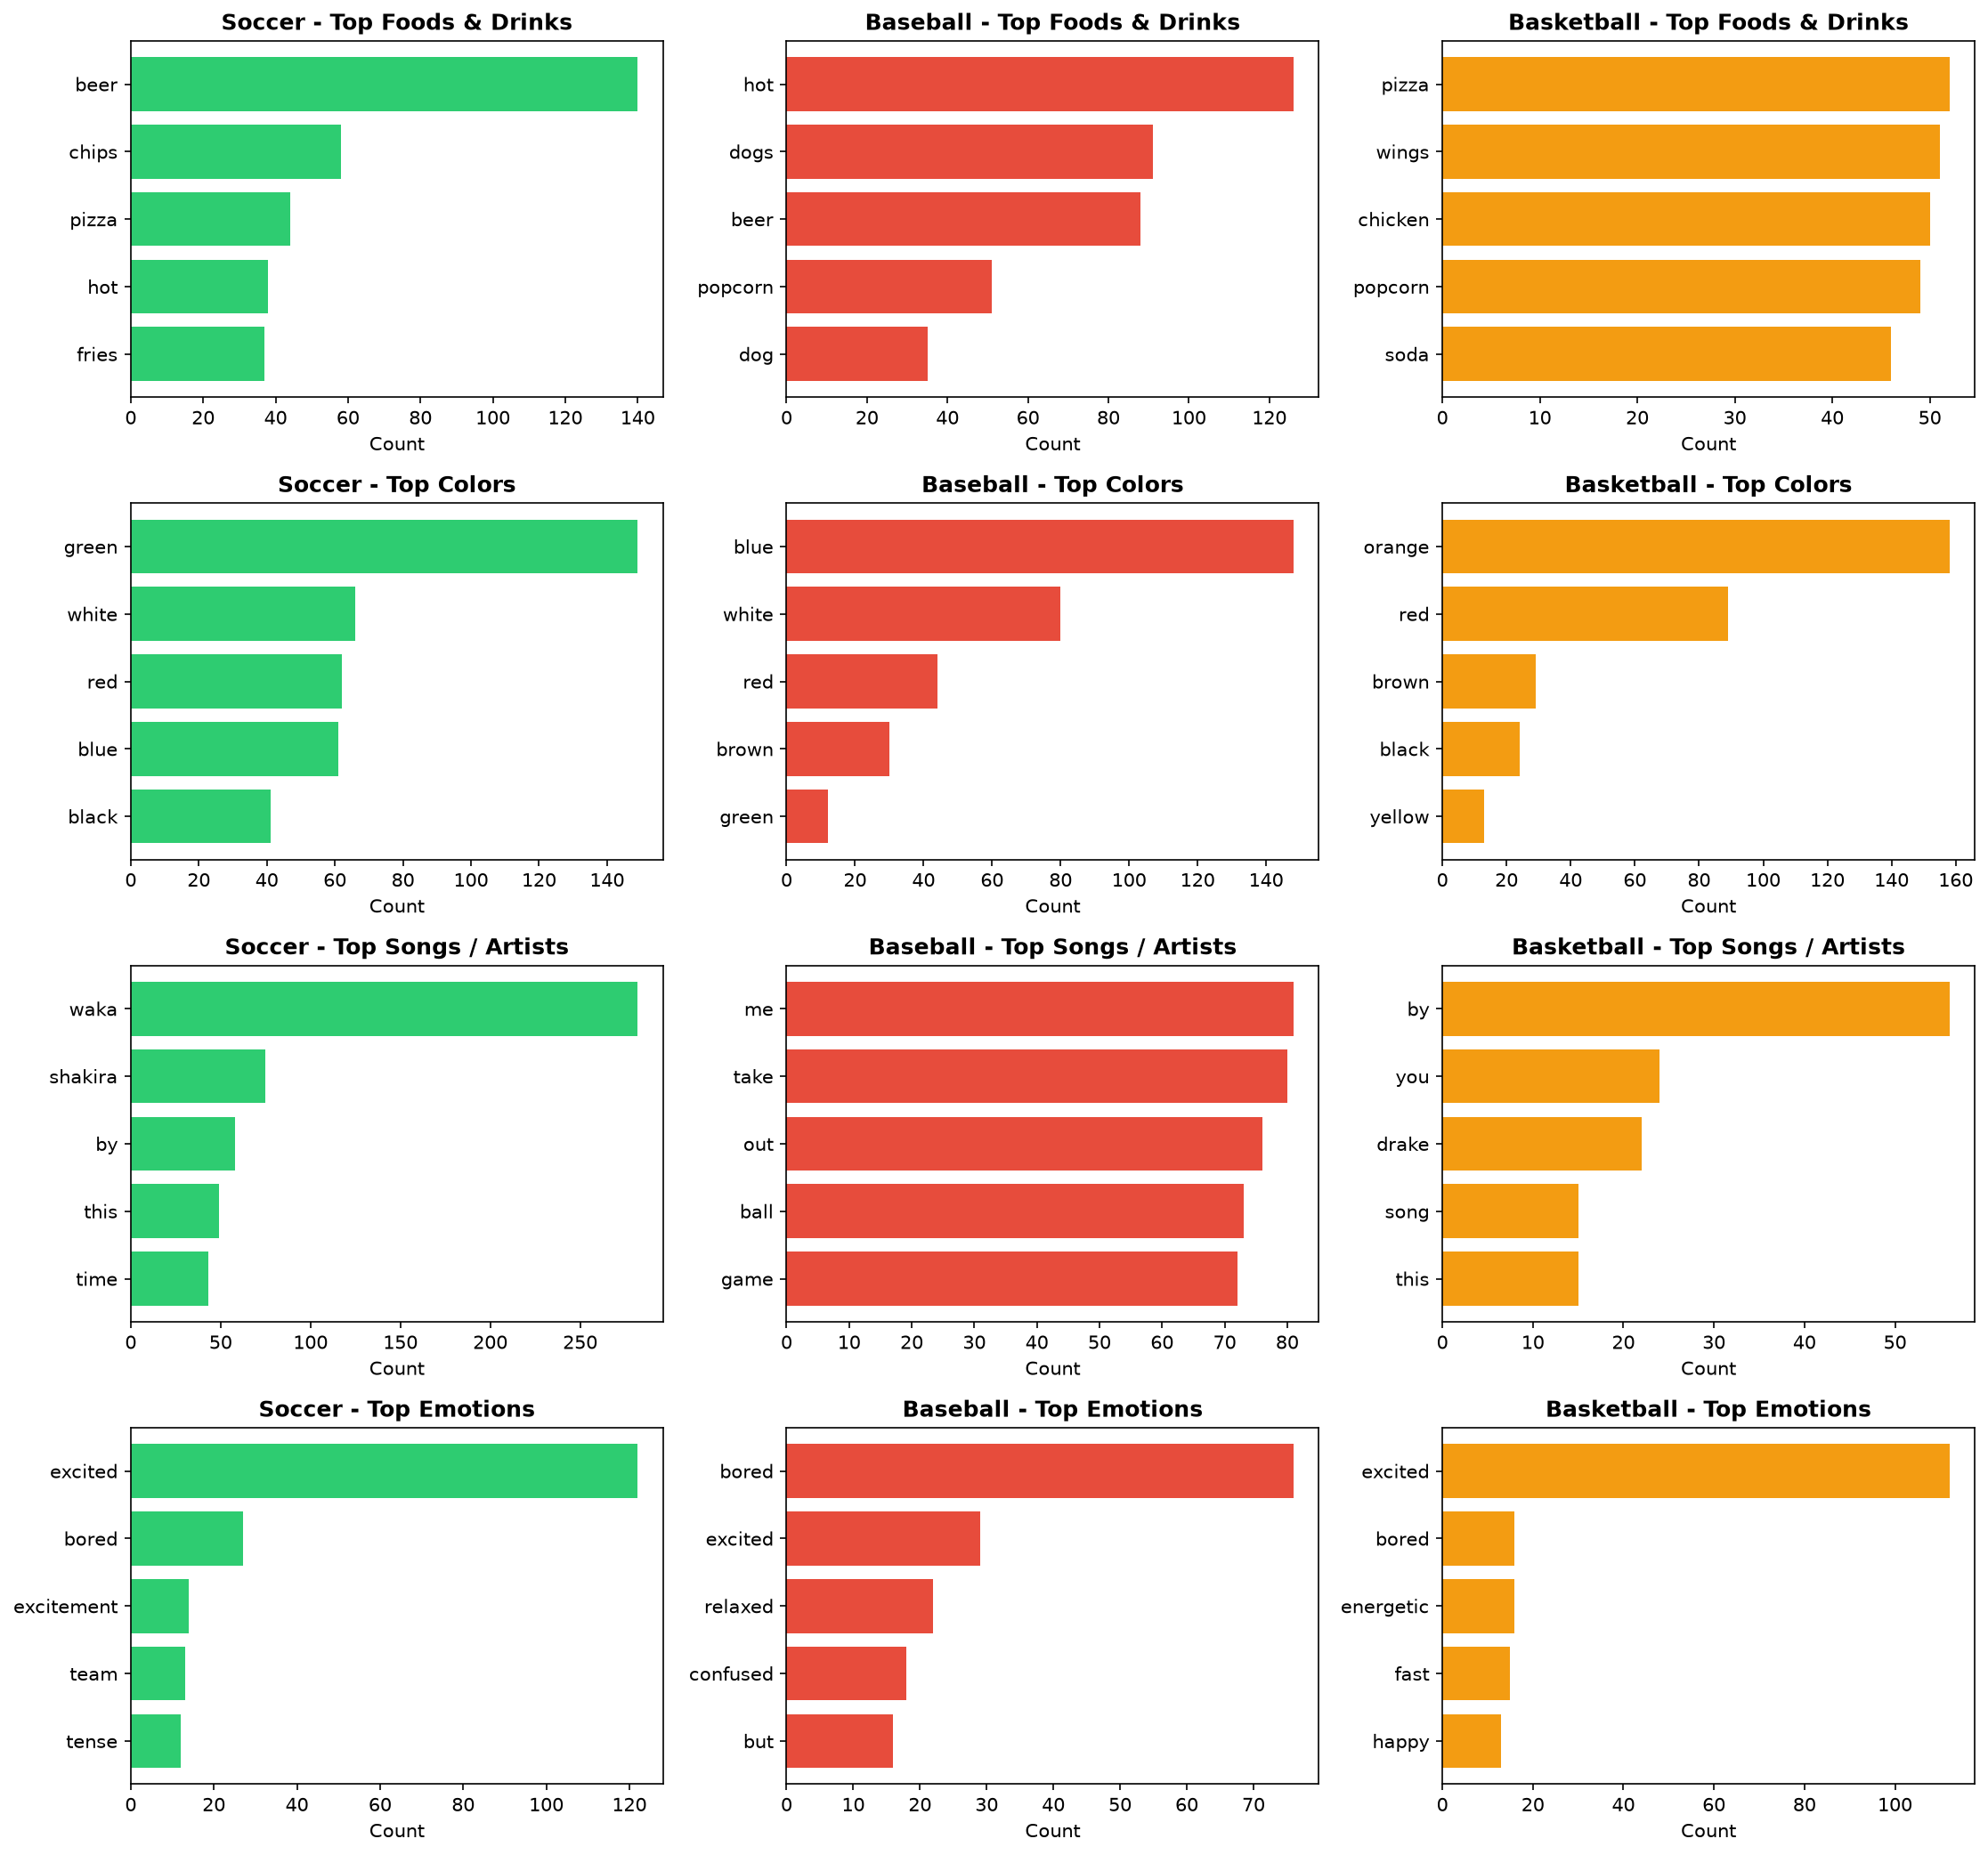

In [2]:
palette = {'Soccer': '#2ecc71', 'Baseball': '#e74c3c', 'Basketball': '#f39c12'}

# 1. Bar plots for Numerical & Likert traits
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
num_cols = [
    ('difficulty_rating', 'Ease of Starting (0-10)'),
    ('strategy_importance_num', 'Strategy Importance (1-5)'),
    ('injury_risk_comfort_num', 'Injury Risk Comfort (1-5)'),
    ('individual_brilliance_num', 'Individual Brilliance (1-5)'),
    ('price_clean', 'Ticket Price ($)'),
    ('log_price', 'Log(1 + Price) ($)')
]

for idx, (col, title) in enumerate(num_cols):
    ax = axes[idx // 3, idx % 3]
    sns.barplot(data=eda_df, x=label_col, y=col, ax=ax, palette=palette, capsize=0.1, estimator=np.nanmean)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Mean')
plt.tight_layout()
plt.show()

# 2. Grouped bar plots for Multi-select categorical features
multi_cols = [
    ('play_season', 'Preferred Seasons to Play in Toronto'),
    ('play_location', 'Playing Locations'),
    ('associated_music', 'Associated Music Genres')
]
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for idx, (col, title) in enumerate(multi_cols):
    expanded = []
    for _, row in eda_df.dropna(subset=[col, label_col]).iterrows():
        sport = row[label_col]
        items = [x.strip() for x in str(row[col]).split(',') if x.strip()]
        for item in items:
            expanded.append({'sport': sport, 'category': item})
    df_cat = pd.DataFrame(expanded)
    sport_counts = eda_df[label_col].value_counts()
    cat_pct = (df_cat.groupby(['category', 'sport']).size().unstack(fill_value=0)).div(sport_counts, axis=1) * 100
    avail = [s for s in ['Soccer', 'Baseball', 'Basketball'] if s in cat_pct.columns]
    cat_pct[avail].plot(kind='bar', ax=axes[idx], color=['#2ecc71', '#e74c3c', '#f39c12'], width=0.75)
    axes[idx].set_title(title)
    axes[idx].set_ylabel('% of Responses')
    axes[idx].set_xlabel('')
    axes[idx].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

# 3. Bar plots for Free-text top 5 keywords
text_cols = [
    ('associated_foods_drinks', 'Top Foods & Drinks'),
    ('associated_color', 'Top Colors'),
    ('associated_song', 'Top Songs / Artists'),
    ('emotional_response', 'Top Emotions')
]
stop_words = {
    'and', 'or', 'the', 'a', 'an', 'in', 'on', 'with', 'to', 'of', 'for',
    'is', 'it', 'sport', 'watching', 'feel', 'when', 'i', 'na', 'n/a', 'none', 'no'
}
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for r_idx, (col, title) in enumerate(text_cols):
    for c_idx, sport in enumerate(['Soccer', 'Baseball', 'Basketball']):
        ax = axes[r_idx, c_idx]
        text_data = eda_df[eda_df[label_col] == sport][col].dropna()
        all_words = []
        for text in text_data:
            words = re.findall(r'\b[a-zA-Z]{2,}\b', str(text).lower())
            all_words.extend([w for w in words if w not in stop_words])
        top_words = Counter(all_words).most_common(5)
        if top_words:
            words, counts = zip(*top_words)
            ax.barh(range(len(words)), counts, color=['#2ecc71', '#e74c3c', '#f39c12'][c_idx])
            ax.set_yticks(range(len(words)))
            ax.set_yticklabels(words)
            ax.invert_yaxis()
        ax.set_title(f'{sport} - {title}')
        ax.set_xlabel('Count')
plt.tight_layout()
plt.show()



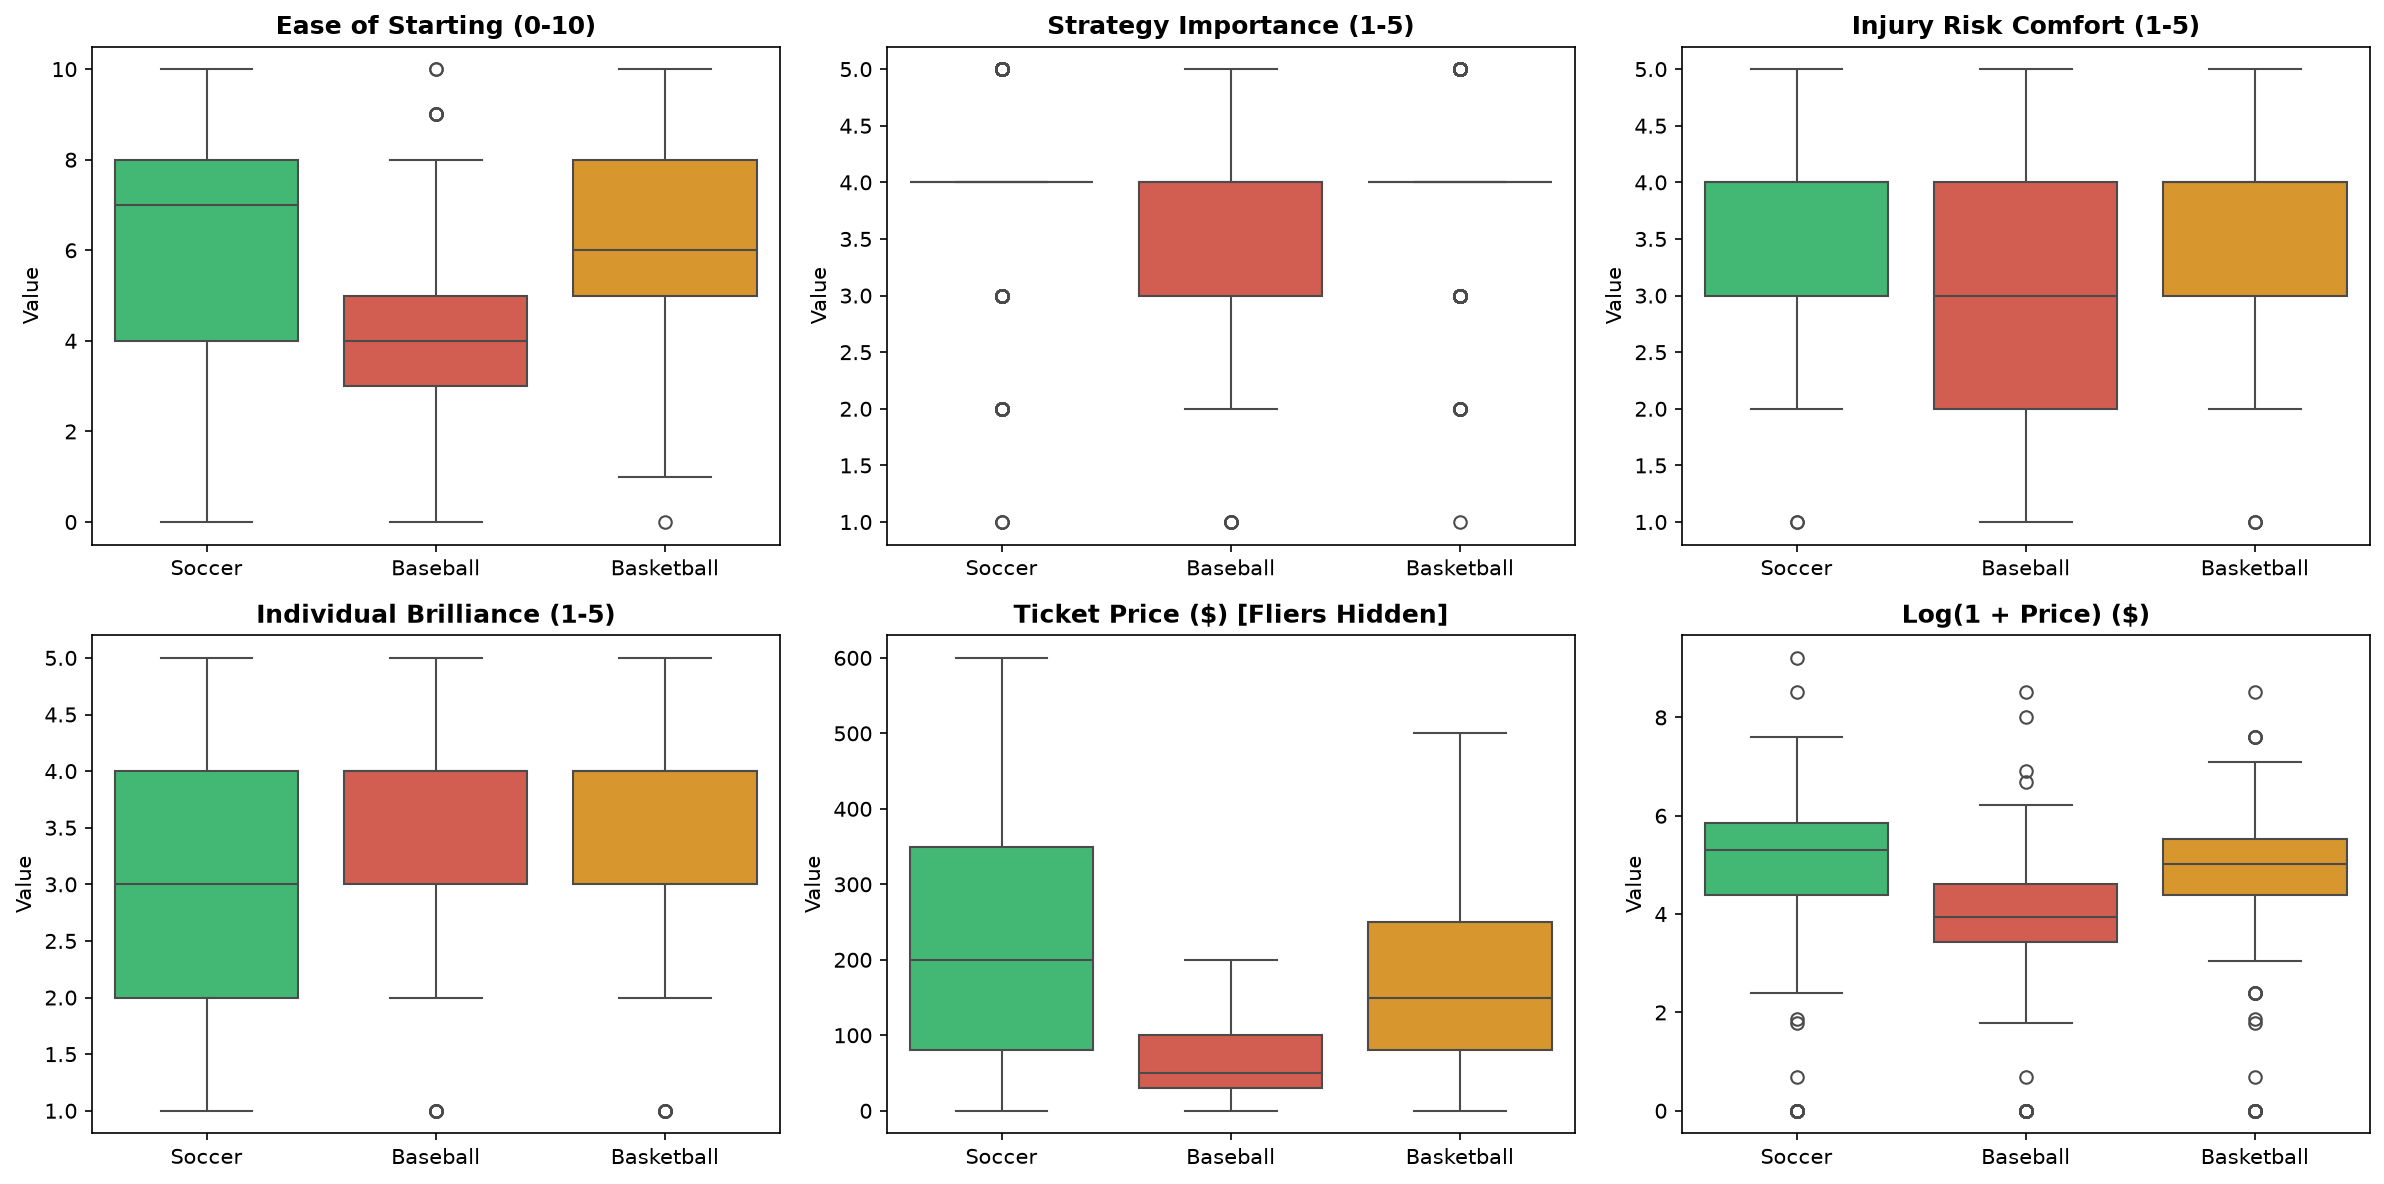

In [3]:
# Box plots for all numerical and ordinal features
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
box_cols = [
    ('difficulty_rating', 'Ease of Starting (0-10)'),
    ('strategy_importance_num', 'Strategy Importance (1-5)'),
    ('injury_risk_comfort_num', 'Injury Risk Comfort (1-5)'),
    ('individual_brilliance_num', 'Individual Brilliance (1-5)'),
    ('price_clean', 'Ticket Price ($) [Fliers Hidden]'),
    ('log_price', 'Log(1 + Price) ($)')
]

for idx, (col, title) in enumerate(box_cols):
    ax = axes[idx // 3, idx % 3]
    show_fliers = False if col == 'price_clean' else True
    sns.boxplot(data=eda_df, x=label_col, y=col, ax=ax, palette=palette, showfliers=show_fliers)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Value')

plt.tight_layout()
plt.show()

